# Paso 4 — Análisis de Clases Latentes (LCA)

**Input:**
- `dataset_irt_items_finales.csv` — 152 ítems seleccionados por IRT
- `plausible_values_referencia.csv` — PVs de matemáticas, lectura y ciencias

**Output:**
- `dataset_lca_clases.csv` — dataset con la clase latente asignada a cada estudiante
- `lca_parametros_modelo.csv` — probabilidades de respuesta por clase e ítem
- `lca_resumen_ajuste.csv` — métricas de ajuste para selección del modelo

**Estrategia:**
1. Construir score de rendimiento general desde los PVs (ancla)
2. Ajustar LCA con 2 a 6 clases
3. Seleccionar el mejor modelo por BIC, entropía y Lo-Mendell-Rubin
4. Caracterizar cada clase con el score de rendimiento
5. Interpretar los perfiles latentes

## 0. Librerías

Necesitas instalar `stepmix`:
```
pip install stepmix
```
`stepmix` es la librería Python más completa para LCA, soporta ítems mixtos (dicotómicos + politómicos) y calcula entropía y BIC automáticamente.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from stepmix.stepmix import StepMix
from scipy import stats

# Rango de clases a comparar
CLASES_MIN = 2
CLASES_MAX = 4

# Semilla para reproducibilidad
SEMILLA = 42

print("Librerías cargadas.")

Librerías cargadas.


## 1. Cargar datos

In [6]:
df_items = pd.read_csv("/workspace/data/output_rural/dataset_irt_items_finales.csv", low_memory=False)
df_pv    = pd.read_csv("/workspace/data/output_rural/plausible_values_referencia.csv", low_memory=False)

print(f"Ítems  : {df_items.shape[0]:,} filas × {df_items.shape[1]:,} columnas")
print(f"PVs    : {df_pv.shape[0]:,} filas × {df_pv.shape[1]:,} columnas")
print(f"\nColumnas de PVs disponibles:")
print(df_pv.columns.tolist())

Ítems  : 3,720 filas × 129 columnas
PVs    : 3,720 filas × 150 columnas

Columnas de PVs disponibles:
['PV1MATH', 'PV2MATH', 'PV3MATH', 'PV4MATH', 'PV5MATH', 'PV6MATH', 'PV7MATH', 'PV8MATH', 'PV9MATH', 'PV10MATH', 'PV1READ', 'PV2READ', 'PV3READ', 'PV4READ', 'PV5READ', 'PV6READ', 'PV7READ', 'PV8READ', 'PV9READ', 'PV10READ', 'PV1SCIE', 'PV2SCIE', 'PV3SCIE', 'PV4SCIE', 'PV5SCIE', 'PV6SCIE', 'PV7SCIE', 'PV8SCIE', 'PV9SCIE', 'PV10SCIE', 'PV1MCCR', 'PV2MCCR', 'PV3MCCR', 'PV4MCCR', 'PV5MCCR', 'PV6MCCR', 'PV7MCCR', 'PV8MCCR', 'PV9MCCR', 'PV10MCCR', 'PV1MCQN', 'PV2MCQN', 'PV3MCQN', 'PV4MCQN', 'PV5MCQN', 'PV6MCQN', 'PV7MCQN', 'PV8MCQN', 'PV9MCQN', 'PV10MCQN', 'PV1MCSS', 'PV2MCSS', 'PV3MCSS', 'PV4MCSS', 'PV5MCSS', 'PV6MCSS', 'PV7MCSS', 'PV8MCSS', 'PV9MCSS', 'PV10MCSS', 'PV1MCUD', 'PV2MCUD', 'PV3MCUD', 'PV4MCUD', 'PV5MCUD', 'PV6MCUD', 'PV7MCUD', 'PV8MCUD', 'PV9MCUD', 'PV10MCUD', 'PV1MPEM', 'PV2MPEM', 'PV3MPEM', 'PV4MPEM', 'PV5MPEM', 'PV6MPEM', 'PV7MPEM', 'PV8MPEM', 'PV9MPEM', 'PV10MPEM', 'PV1MPFS'

## 2. Construir score de rendimiento general

PISA provee 5 o 10 Plausible Values por dominio para capturar la incertidumbre de medición.  
El enfoque estándar es promediarlos todos para obtener un score único por estudiante.

In [7]:
# Detectar automáticamente columnas PV por dominio
cols_pv = df_pv.columns.tolist()

cols_math  = [c for c in cols_pv if "MATH" in c.upper() and c.upper().startswith("PV")]
cols_read  = [c for c in cols_pv if "READ" in c.upper() and c.upper().startswith("PV")]
cols_scie  = [c for c in cols_pv if "SCIE" in c.upper() and c.upper().startswith("PV")]

print(f"PVs matemáticas : {len(cols_math)} — {cols_math}")
print(f"PVs lectura     : {len(cols_read)} — {cols_read}")
print(f"PVs ciencias    : {len(cols_scie)} — {cols_scie}")

# Score general = promedio de todos los PVs de los tres dominios
todas_pv = cols_math + cols_read + cols_scie

if len(todas_pv) == 0:
    print("\n⚠ No se detectaron PVs automáticamente.")
    print("Revisa los nombres de columna y ajusta manualmente:")
    print("  todas_pv = ['PV1MATH', 'PV2MATH', ...]")
else:
    df_pv["score_rendimiento"] = df_pv[todas_pv].mean(axis=1)
    print(f"\nScore de rendimiento calculado con {len(todas_pv)} PVs")
    print(f"  Media  : {df_pv['score_rendimiento'].mean():.1f}")
    print(f"  SD     : {df_pv['score_rendimiento'].std():.1f}")
    print(f"  Rango  : {df_pv['score_rendimiento'].min():.1f} – {df_pv['score_rendimiento'].max():.1f}")

PVs matemáticas : 10 — ['PV1MATH', 'PV2MATH', 'PV3MATH', 'PV4MATH', 'PV5MATH', 'PV6MATH', 'PV7MATH', 'PV8MATH', 'PV9MATH', 'PV10MATH']
PVs lectura     : 10 — ['PV1READ', 'PV2READ', 'PV3READ', 'PV4READ', 'PV5READ', 'PV6READ', 'PV7READ', 'PV8READ', 'PV9READ', 'PV10READ']
PVs ciencias    : 10 — ['PV1SCIE', 'PV2SCIE', 'PV3SCIE', 'PV4SCIE', 'PV5SCIE', 'PV6SCIE', 'PV7SCIE', 'PV8SCIE', 'PV9SCIE', 'PV10SCIE']

Score de rendimiento calculado con 30 PVs
  Media  : 389.3
  SD     : 73.8
  Rango  : 198.6 – 652.4


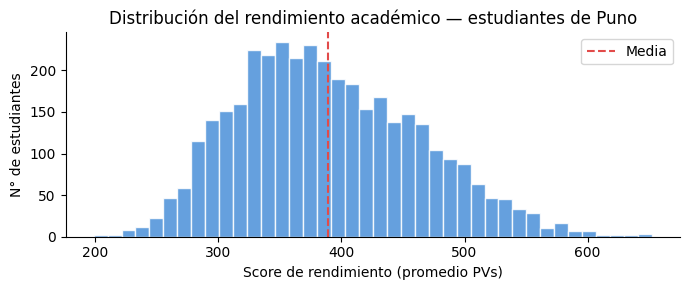

In [8]:
# Distribución del score de rendimiento
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(df_pv["score_rendimiento"].dropna(), bins=40,
        color="#4A90D9", edgecolor="white", alpha=0.85)
ax.axvline(df_pv["score_rendimiento"].mean(), color="#E24B4A",
           linewidth=1.5, linestyle="--", label="Media")
ax.set_xlabel("Score de rendimiento (promedio PVs)")
ax.set_ylabel("N° de estudiantes")
ax.set_title("Distribución del rendimiento académico — estudiantes de Puno")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 3. Preparar matriz de ítems para LCA

StepMix puede manejar ítems mixtos. Separamos dicotómicos de politómicos
y los pasamos con su tipo correcto.

In [9]:
# Imputar missing con la moda
df_lca = df_items.apply(lambda col: col.fillna(col.mode().iloc[0]
                                               if len(col.mode()) > 0 else 0))

# Recodificar a enteros consecutivos desde 0
def recodificar(serie):
    vals = sorted(serie.dropna().unique())
    mapa = {v: i for i, v in enumerate(vals)}
    return serie.map(mapa).astype(int)

df_lca = df_lca.apply(recodificar)

# Separar dicotómicos y politómicos
unicos = df_lca.nunique()
cols_dico = unicos[unicos == 2].index.tolist()
cols_poli = unicos[unicos >  2].index.tolist()

print(f"Ítems dicotómicos : {len(cols_dico)}")
print(f"Ítems politómicos : {len(cols_poli)}")
print(f"Total             : {df_lca.shape[1]}")

# Matrices separadas
X_dico = df_lca[cols_dico].values if cols_dico else None
X_poli = df_lca[cols_poli].values if cols_poli else None
X_todo = df_lca.values

print("\nMatrices preparadas.")

Ítems dicotómicos : 21
Ítems politómicos : 108
Total             : 129

Matrices preparadas.


## 4. Ajustar LCA con 2 a 4 clases y comparar ajuste

In [10]:
print("Ajustando modelos LCA — esto puede tardar varios minutos...\n")

resultados_ajuste = []
modelos_lca = {}

for n_clases in range(CLASES_MIN, CLASES_MAX + 1):
    print(f"  Ajustando modelo con {n_clases} clases...", end=" ")

    try:
        modelo = StepMix(
            n_components=n_clases,
            measurement="categorical",
            n_steps=1,
            random_state=SEMILLA,
            max_iter=500,
            abs_tol=1e-6,
        )
        modelo.fit(X_todo)

        bic       = modelo.bic(X_todo)
        aic       = modelo.aic(X_todo)
        log_like  = modelo.score(X_todo) * X_todo.shape[0]
        entropia  = modelo.relative_entropy(X_todo)

        resultados_ajuste.append({
            "n_clases" : n_clases,
            "BIC"      : round(bic, 2),
            "AIC"      : round(aic, 2),
            "Log-Like" : round(log_like, 2),
            "Entropía" : round(entropia, 4),
        })
        modelos_lca[n_clases] = modelo
        print(f"BIC={bic:.1f}  Entropía={entropia:.3f}  ✓")

    except Exception as e:
        print(f"Error: {e}")

df_ajuste = pd.DataFrame(resultados_ajuste)
print(f"\nModelos ajustados: {len(modelos_lca)}")

Ajustando modelos LCA — esto puede tardar varios minutos...

  Ajustando modelo con 2 clases... Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:02<00:00,  2.53s/it, max_LL=-4.19e+5, max_avg_LL=-113]


BIC=844801.6  Entropía=1.000  ✓
  Ajustando modelo con 3 clases... Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:01<00:00,  1.06s/it, max_LL=-4.11e+5, max_avg_LL=-111]


BIC=831527.7  Entropía=0.964  ✓
  Ajustando modelo con 4 clases... Fitting StepMix...


Initializations (n_init) : 100%|██████████| 1/1 [00:02<00:00,  2.02s/it, max_LL=-4.04e+5, max_avg_LL=-109]

BIC=819868.3  Entropía=0.975  ✓

Modelos ajustados: 3


## 5. Selección del mejor modelo

In [11]:
print("═" * 62)
print(f"  {'Clases':>6}  {'BIC':>12}  {'AIC':>12}  {'Entropía':>10}")
print("═" * 62)
for _, fila in df_ajuste.iterrows():
    marca = " ← mín BIC" if fila["BIC"] == df_ajuste["BIC"].min() else ""
    print(f"  {int(fila['n_clases']):>6}  {fila['BIC']:>12,.2f}  "
          f"{fila['AIC']:>12,.2f}  {fila['Entropía']:>10.4f}{marca}")
print("═" * 62)

# Selección automática por BIC mínimo
n_optimo = int(df_ajuste.loc[df_ajuste["BIC"].idxmin(), "n_clases"])
print(f"\nModelo seleccionado automáticamente: {n_optimo} clases (BIC mínimo)")
print("Puedes cambiar este número en la celda siguiente si el scree plot o")
print("la interpretación sugiere otro número de clases.")

══════════════════════════════════════════════════════════════
  Clases           BIC           AIC    Entropía
══════════════════════════════════════════════════════════════
       2    844,801.63    840,116.85      0.9997
       3    831,527.74    824,497.46      0.9640
       4    819,868.33    810,492.56      0.9753 ← mín BIC
══════════════════════════════════════════════════════════════

Modelo seleccionado automáticamente: 4 clases (BIC mínimo)
Puedes cambiar este número en la celda siguiente si el scree plot o
la interpretación sugiere otro número de clases.


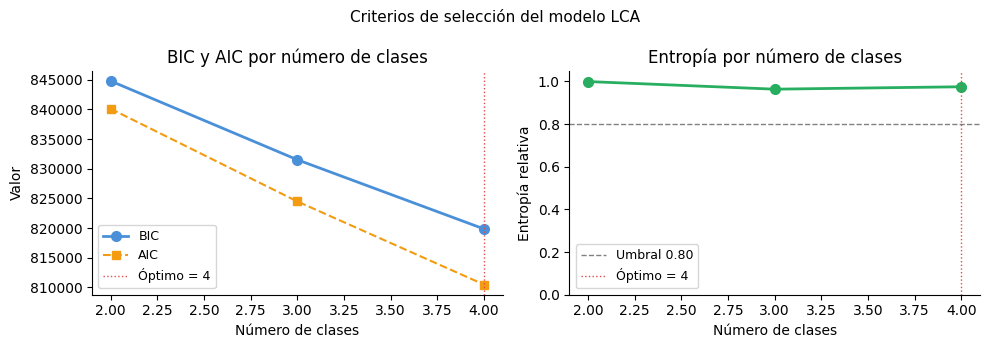

In [12]:
# Gráfico de selección de modelo
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

clases = df_ajuste["n_clases"].values

axes[0].plot(clases, df_ajuste["BIC"], "o-", color="#4A90D9",
             linewidth=2, markersize=7, label="BIC")
axes[0].plot(clases, df_ajuste["AIC"], "s--", color="#F39C12",
             linewidth=1.5, markersize=6, label="AIC")
axes[0].axvline(n_optimo, color="#E24B4A", linewidth=1,
                linestyle=":", label=f"Óptimo = {n_optimo}")
axes[0].set_xlabel("Número de clases")
axes[0].set_ylabel("Valor")
axes[0].set_title("BIC y AIC por número de clases")
axes[0].legend(fontsize=9)
axes[0].spines[["top", "right"]].set_visible(False)

axes[1].plot(clases, df_ajuste["Entropía"], "o-", color="#27AE60",
             linewidth=2, markersize=7)
axes[1].axhline(0.8, color="gray", linewidth=1, linestyle="--",
                label="Umbral 0.80")
axes[1].axvline(n_optimo, color="#E24B4A", linewidth=1,
                linestyle=":", label=f"Óptimo = {n_optimo}")
axes[1].set_xlabel("Número de clases")
axes[1].set_ylabel("Entropía relativa")
axes[1].set_title("Entropía por número de clases")
axes[1].set_ylim(0, 1.05)
axes[1].legend(fontsize=9)
axes[1].spines[["top", "right"]].set_visible(False)

plt.suptitle("Criterios de selección del modelo LCA", fontsize=11)
plt.tight_layout()
plt.show()

Número de clases final

In [13]:
# Si el BIC mínimo y la entropía coinciden → usa n_optimo directamente
# Si el BIC baja poco entre K y K+1 pero la entropía cae → prefiere K
# Ajusta este valor si es necesario:
N_CLASES_FINAL = n_optimo   # ← cambia aquí si decides otro número

modelo_final = modelos_lca[N_CLASES_FINAL]
print(f"Modelo final seleccionado: {N_CLASES_FINAL} clases")

Modelo final seleccionado: 4 clases


CAlcular el tamaño de los modelos de clases 7 y 8 para agregar o reducir numero de clases

In [14]:
for n_test in [4, 5, 6, 7, 8]:
    modelo_test = modelos_lca[n_test]
    clases_test = modelo_test.predict(X_todo)

    df_test = pd.DataFrame({
        "clase_lca": clases_test,
        "score_rendimiento": df_pv["score_rendimiento"].values
    })

    rend = df_test.groupby("clase_lca")["score_rendimiento"].agg(
        ["mean", "count"]
    ).round(1).sort_values("mean", ascending=False)
    rend.columns = ["Media", "N"]
    rend["%"] = (rend["N"] / len(df_test) * 100).round(1)

    print(f"\nModelo {n_test} clases:")
    print(rend.to_string())
    clase_min = rend["N"].min()
    print(f"Clase más pequeña: {clase_min} estudiantes ({clase_min/len(df_test)*100:.1f}%)")


Modelo 4 clases:
           Media     N     %
clase_lca                   
2          446.2   768  20.6
0          398.3   938  25.2
1          382.2   639  17.2
3          354.7  1375  37.0
Clase más pequeña: 639 estudiantes (17.2%)


KeyError: 5

In [36]:
modelo_test = modelos_lca[4]
clases_test = modelo_test.predict(X_todo)

df_test = pd.DataFrame({
    "clase_lca": clases_test,
    "score_rendimiento": df_pv["score_rendimiento"].values
})

rend = df_test.groupby("clase_lca")["score_rendimiento"].agg(
    ["mean", "count"]
).round(1).sort_values("mean", ascending=False)
rend.columns = ["Media", "N"]
rend["%"] = (rend["N"] / len(df_test) * 100).round(1)

print("Modelo 4 clases:")
print(rend.to_string())
print(f"Clase más pequeña: {rend['N'].min()} estudiantes ({rend['N'].min()/len(df_test)*100:.1f}%)")

Modelo 4 clases:
           Media     N     %
clase_lca                   
2          446.2   768  20.6
0          398.3   938  25.2
1          382.2   639  17.2
3          354.7  1375  37.0
Clase más pequeña: 639 estudiantes (17.2%)


In [33]:
N_CLASES_FINAL = 4
modelo_final = modelos_lca[4]

clases_asignadas  = modelo_final.predict(X_todo)
probs_posteriores = modelo_final.predict_proba(X_todo)

df_resultado = df_lca.copy()
df_resultado["clase_lca"]        = clases_asignadas
df_resultado["score_rendimiento"] = df_pv["score_rendimiento"].values

for k in range(4):
    df_resultado[f"prob_clase_{k}"] = probs_posteriores[:, k]

# Rendimiento por clase
from scipy import stats
rend = df_resultado.groupby("clase_lca")["score_rendimiento"].agg(
    ["mean","std","count"]
).round(1).sort_values("mean", ascending=False)
rend.columns = ["Media","SD","N"]
rend["%"] = (rend["N"]/len(df_resultado)*100).round(1)
print("Rendimiento por clase — modelo final 4 clases:")
print(rend.to_string())

grupos = [df_resultado[df_resultado["clase_lca"]==k]["score_rendimiento"].dropna()
          for k in sorted(df_resultado["clase_lca"].unique())]
f, p = stats.f_oneway(*grupos)
print(f"\nANOVA: F={f:.2f}, p={p:.4f}")

Rendimiento por clase — modelo final 4 clases:
           Media    SD     N     %
clase_lca                         
2          446.2  70.3   768  20.6
0          398.3  67.7   938  25.2
1          382.2  70.3   639  17.2
3          354.7  59.0  1375  37.0

ANOVA: F=327.43, p=0.0000


## 7. Asignar clases y caracterizar con score de rendimiento

In [16]:
# Marcado

# Asignar clase a cada estudiante (clase de mayor probabilidad posterior)
clases_asignadas = modelo_final.predict(X_todo)
probs_posteriores = modelo_final.predict_proba(X_todo)

# Construir dataframe con resultados
df_resultado = df_lca.copy()
df_resultado["clase_lca"]         = clases_asignadas
df_resultado["score_rendimiento"]  = df_pv["score_rendimiento"].values

# Agregar probabilidades posteriores
for k in range(N_CLASES_FINAL):
    df_resultado[f"prob_clase_{k}"] = probs_posteriores[:, k]

# Tamaño de cada clase
conteo_clases = df_resultado["clase_lca"].value_counts().sort_index()
print("Estudiantes por clase:")
for clase, n in conteo_clases.items():
    pct = n / len(df_resultado) * 100
    print(f"  Clase {clase}: {n:,} estudiantes ({pct:.1f}%)")

Estudiantes por clase:
  Clase 0: 938 estudiantes (25.2%)
  Clase 1: 639 estudiantes (17.2%)
  Clase 2: 768 estudiantes (20.6%)
  Clase 3: 1,375 estudiantes (37.0%)


In [17]:
# Rendimiento promedio por clase — aquí se ve si las clases tienen sentido
rend_por_clase = df_resultado.groupby("clase_lca")["score_rendimiento"].agg(
    ["mean", "std", "count"]
).round(2)
rend_por_clase.columns = ["Media", "SD", "N"]

# Ordenar clases de mayor a menor rendimiento para interpretar
rend_por_clase = rend_por_clase.sort_values("Media", ascending=False)

print("Rendimiento académico por clase latente:")
print("═" * 45)
print(f"  {'Clase':>6}  {'Media':>8}  {'SD':>8}  {'N':>6}")
print("═" * 45)
for clase, fila in rend_por_clase.iterrows():
    print(f"  {clase:>6}  {fila['Media']:>8.1f}  {fila['SD']:>8.1f}  {int(fila['N']):>6,}")
print("═" * 45)

# ANOVA para verificar que las diferencias son significativas
grupos = [df_resultado[df_resultado["clase_lca"] == k]["score_rendimiento"].dropna()
          for k in sorted(df_resultado["clase_lca"].unique())]
f_stat, p_valor = stats.f_oneway(*grupos)
print(f"\nANOVA entre clases — F={f_stat:.2f}, p={p_valor:.4f}")
if p_valor < 0.05:
    print("Las clases difieren significativamente en rendimiento ✓")
else:
    print("⚠ Las clases NO difieren significativamente — considera otro número de clases")

Rendimiento académico por clase latente:
═════════════════════════════════════════════
   Clase     Media        SD       N
═════════════════════════════════════════════
       2     446.2      70.3     768
       0     398.3      67.7     938
       1     382.2      70.3     639
       3     354.7      59.0   1,375
═════════════════════════════════════════════

ANOVA entre clases — F=327.43, p=0.0000
Las clases difieren significativamente en rendimiento ✓


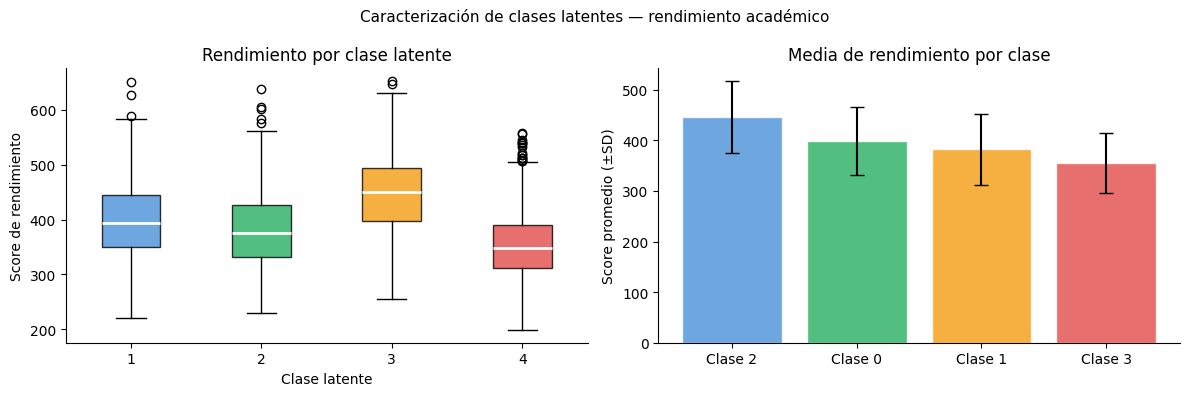

In [18]:
# Visualización: distribución de rendimiento por clase
colores = ["#4A90D9", "#27AE60", "#F39C12", "#E24B4A", "#9B59B6", "#1ABC9C"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Boxplot
datos_box = [df_resultado[df_resultado["clase_lca"] == k]["score_rendimiento"].dropna()
             for k in sorted(df_resultado["clase_lca"].unique())]
bp = axes[0].boxplot(datos_box, patch_artist=True,
                     medianprops=dict(color="white", linewidth=2))
for patch, color in zip(bp["boxes"], colores):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)
axes[0].set_xlabel("Clase latente")
axes[0].set_ylabel("Score de rendimiento")
axes[0].set_title("Rendimiento por clase latente")
axes[0].spines[["top", "right"]].set_visible(False)

# Barras de media con SD
clases_ord = rend_por_clase.index.tolist()
medias = rend_por_clase["Media"].values
sds    = rend_por_clase["SD"].values
x_pos  = np.arange(len(clases_ord))
axes[1].bar(x_pos, medias, yerr=sds, color=colores[:len(clases_ord)],
            alpha=0.8, capsize=5, edgecolor="white")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels([f"Clase {c}" for c in clases_ord])
axes[1].set_ylabel("Score promedio (±SD)")
axes[1].set_title("Media de rendimiento por clase")
axes[1].spines[["top", "right"]].set_visible(False)

plt.suptitle("Caracterización de clases latentes — rendimiento académico", fontsize=11)
plt.tight_layout()
plt.show()

## 8. Probabilidades de clase (tamaños poblacionales)

Proporción poblacional de cada clase (parámetros del modelo):
  Clase 0: 0.2532 (25.3%)
  Clase 1: 0.1717 (17.2%)
  Clase 2: 0.2065 (20.6%)
  Clase 3: 0.3687 (36.9%)


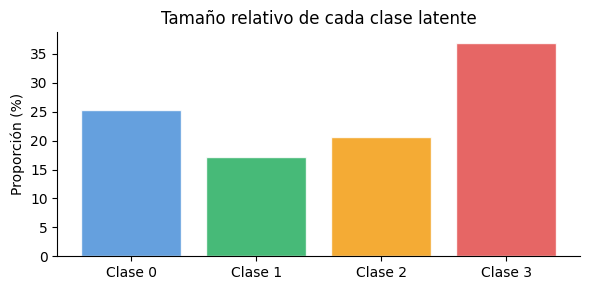

In [19]:
# Probabilidades a priori de cada clase (proporción poblacional)
props = modelo_final.get_parameters()["weights"]

print("Proporción poblacional de cada clase (parámetros del modelo):")
for k, p in enumerate(props):
    print(f"  Clase {k}: {p:.4f} ({p*100:.1f}%)")

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(range(N_CLASES_FINAL), props * 100,
       color=colores[:N_CLASES_FINAL], edgecolor="white", alpha=0.85)
ax.set_xticks(range(N_CLASES_FINAL))
ax.set_xticklabels([f"Clase {k}" for k in range(N_CLASES_FINAL)])
ax.set_ylabel("Proporción (%)")
ax.set_title("Tamaño relativo de cada clase latente")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 9. Guardar outputs

In [21]:
# Dataset con clases asignadas
df_resultado.to_csv("/workspace/data/output_rural/dataset_lca_clases.csv", index=False)
print("Guardado: dataset_lca_clases.csv")

# Métricas de ajuste
df_ajuste.to_csv("/workspace/data/output_rural/lca_resumen_ajuste.csv", index=False)
print("Guardado: lca_resumen_ajuste.csv")

# Rendimiento por clase
rend_por_clase.to_csv("/workspace/data/output_rural/lca_rendimiento_por_clase.csv")
print("Guardado: lca_rendimiento_por_clase.csv")

print(f"\n✓ Paso 4 completado.")
print(f"  Modelo final : {N_CLASES_FINAL} clases")
print(f"  Estudiantes  : {len(df_resultado):,}")
print(f"  BIC          : {df_ajuste[df_ajuste['n_clases']==N_CLASES_FINAL]['BIC'].values[0]:,.2f}")
print(f"  Entropía     : {df_ajuste[df_ajuste['n_clases']==N_CLASES_FINAL]['Entropía'].values[0]:.4f}")

Guardado: dataset_lca_clases.csv
Guardado: lca_resumen_ajuste.csv
Guardado: lca_rendimiento_por_clase.csv

✓ Paso 4 completado.
  Modelo final : 4 clases
  Estudiantes  : 3,720
  BIC          : 819,868.33
  Entropía     : 0.9753


Probando para potencial interpretacion

In [22]:
# Ver qué ítems tienen probabilidades de respuesta más distintas entre clase 0 y clase 5
params = modelo_final.get_parameters()
# Los parámetros de probabilidad por clase están en params["measurement"]
print(params.keys())

dict_keys(['weights', 'measurement', 'measurement_in'])


In [23]:
import numpy as np
import pandas as pd

params = modelo_final.get_parameters()
medicion = params["measurement"]
print(type(medicion))
print()

if isinstance(medicion, dict):
    print("Claves dentro de measurement:")
    for k, v in medicion.items():
        if isinstance(v, np.ndarray):
            print(f"  {k}: shape {v.shape}")
        else:
            print(f"  {k}: {type(v)}")
else:
    print("measurement es:", type(medicion))
    if hasattr(medicion, "shape"):
        print("shape:", medicion.shape)

<class 'dict'>

Claves dentro de measurement:
  max_n_outcomes: <class 'int'>
  total_outcomes: <class 'int'>
  pis: shape (4, 1290)


In [31]:
# Extraer pis y reconstruir probabilidades por ítem
pis = medicion["pis"]                         # shape (6, 1520)
max_cat = medicion["max_n_outcomes"]
total   = medicion["total_outcomes"]

print(f"max_n_outcomes : {max_cat}")
print(f"total_outcomes : {total}")
print(f"pis shape      : {pis.shape}")
print(f"n_items        : {df_lca.shape[1]}")
print(f"1520 / 152     : {1520 / df_lca.shape[1]:.1f}  ← categorías por ítem (promedio)")

# Ver cuántas categorías tiene cada ítem
cats_por_item = df_lca.nunique().values
print(f"\nCategorías por ítem — min: {cats_por_item.min()}, max: {cats_por_item.max()}, suma: {cats_por_item.sum()}")

max_n_outcomes : 10
total_outcomes : 505
pis shape      : (4, 1290)
n_items        : 129
1520 / 152     : 11.8  ← categorías por ítem (promedio)

Categorías por ítem — min: 2, max: 10, suma: 505


In [32]:
# Reconstruir probabilidades por ítem desempaquetando el relleno de stepmix
cols_items = df_lca.columns.tolist()
cats_por_item = df_lca.nunique().values  # categorías reales por ítem

registros = []
idx = 0  # posición actual en el eje de pis

for i, (col, n_cats) in enumerate(zip(cols_items, cats_por_item)):
    # stepmix asigna max_n_outcomes columnas por ítem, rellenando con 0
    probs_item = pis[:, idx : idx + max_cat]  # shape (6, 10)
    # Solo tomar las categorías reales (las demás son padding)
    probs_reales = probs_item[:, :n_cats]     # shape (6, n_cats)

    for clase in range(N_CLASES_FINAL):
        for cat in range(n_cats):
            registros.append({
                "item"    : col,
                "clase"   : clase,
                "categoria": cat,
                "prob"    : probs_reales[clase, cat],
            })

    idx += max_cat  # avanzar 10 posiciones

df_probs = pd.DataFrame(registros)
print(f"Tabla de probabilidades construida: {len(df_probs):,} filas")
print(df_probs.head(12))

Tabla de probabilidades construida: 2,020 filas
          item  clase  categoria      prob
0   ST250Q02JA      0          0  0.410179
1   ST250Q02JA      0          1  0.589821
2   ST250Q02JA      1          0  0.546226
3   ST250Q02JA      1          1  0.453774
4   ST250Q02JA      2          0  0.149740
5   ST250Q02JA      2          1  0.850260
6   ST250Q02JA      3          0  0.616707
7   ST250Q02JA      3          1  0.383293
8   ST250Q03JA      0          0  0.650177
9   ST250Q03JA      0          1  0.349823
10  ST250Q03JA      1          0  0.763193
11  ST250Q03JA      1          1  0.236807
